In [1]:
import pandas as pd
import numpy as np
from sklearn import datasets
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

In [2]:
print("Loading Iris Dataset...")
iris = datasets.load_iris()

iris_data_df = pd.DataFrame(iris.data, columns=iris.feature_names)
iris_target_df = pd.DataFrame(iris.target, columns=['class'])

print("Dataset Info:")
print(f"Dataset shape: {iris_data_df.shape}")
print(f"Target classes: {iris.target_names}")

print("\nFirst 5 rows of features:")
print(iris_data_df.head())

print("\nFirst 5 rows of targets:")
print(iris_target_df.head())

Loading Iris Dataset...
Dataset Info:
Dataset shape: (150, 4)
Target classes: ['setosa' 'versicolor' 'virginica']

First 5 rows of features:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

First 5 rows of targets:
   class
0      0
1      0
2      0
3      0
4      0


In [3]:
X = iris.data
y = iris.target

X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp
)

print("\nData split:")
print(f"Training set: {X_train.shape[0]} samples")
print(f"Validation set: {X_val.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")



Data split:
Training set: 90 samples
Validation set: 30 samples
Test set: 30 samples


In [6]:
def evaluate_model(model, X_test, y_test, kernel_name):
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)

    print(f"\n=== {kernel_name} Kernel Results ===")
    print(f"Accuracy: {accuracy:.4f}")
    print("\nClassification Report:")

    print(classification_report(
        y_test, y_pred,
        target_names=iris.target_names
    ))

    return y_pred, accuracy

In [7]:
kernels_results = {}

print("\n" + "=" * 50)

svc_poly = SVC(
    kernel='poly',
    degree=3,
    gamma='scale',
    random_state=42
)

svc_poly.fit(X_train, y_train)

y_pred_poly, acc_poly = evaluate_model(
    svc_poly, X_val, y_val, "Polynomial"
)

kernels_results['Polynomial'] = acc_poly



=== Polynomial Kernel Results ===
Accuracy: 0.9333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [8]:
svc_rbf = SVC(
    kernel='rbf',
    gamma='scale',
    random_state=42
)

svc_rbf.fit(X_train, y_train)

y_pred_rbf, acc_rbf = evaluate_model(
    svc_rbf, X_val, y_val, "RBF"
)

kernels_results['RBF'] = acc_rbf



=== RBF Kernel Results ===
Accuracy: 0.9333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [9]:
svc_sigmoid = SVC(
    kernel='sigmoid',
    gamma='scale',
    random_state=42
)

svc_sigmoid.fit(X_train, y_train)

y_pred_sigmoid, acc_sigmoid = evaluate_model(
    svc_sigmoid, X_val, y_val, "Sigmoid"
)

kernels_results['Sigmoid'] = acc_sigmoid


=== Sigmoid Kernel Results ===
Accuracy: 0.1333

Classification Report:
              precision    recall  f1-score   support

      setosa       0.18      0.40      0.25        10
  versicolor       0.00      0.00      0.00        10
   virginica       0.00      0.00      0.00        10

    accuracy                           0.13        30
   macro avg       0.06      0.13      0.08        30
weighted avg       0.06      0.13      0.08        30



In [10]:
svc_linear = SVC(
    kernel='linear',
    random_state=42
)

svc_linear.fit(X_train, y_train)

y_pred_linear, acc_linear = evaluate_model(
    svc_linear, X_val, y_val, "Linear"
)

kernels_results['Linear'] = acc_linear



=== Linear Kernel Results ===
Accuracy: 0.9333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [11]:
print("\n" + "=" * 50)
print("KERNEL COMPARISON ON VALIDATION SET:")
print("=" * 50)

for kernel, accuracy in kernels_results.items():
    print(f"{kernel:12}: {accuracy:.4f}")


KERNEL COMPARISON ON VALIDATION SET:
Polynomial  : 0.9333
RBF         : 0.9333
Sigmoid     : 0.1333
Linear      : 0.9333


In [13]:
print("\n" + "=" * 50)
print("HYPERPARAMETER TUNING WITH GRIDSEARCHCV")
print("=" * 50)

param_grid = [
    {
        'kernel': ['rbf'],
        'C': [0.1, 1, 10, 100],
        'gamma': ['scale', 'auto', 0.1, 0.01, 0.001]
    },
    {
        'kernel': ['poly'],
        'C': [0.1, 1, 10, 100],
        'gamma': ['scale', 'auto', 0.1, 0.01, 0.001],
        'degree': [2, 3, 4]
    },
    {
        'kernel': ['sigmoid'],
        'C': [0.1, 1, 10, 100],
        'gamma': ['scale', 'auto', 0.1, 0.01, 0.001]
    },
    {
        'kernel': ['linear'],
        'C': [0.1, 1, 10, 100]
    }
]


HYPERPARAMETER TUNING WITH GRIDSEARCHCV


In [14]:
grid_search = GridSearchCV(
    SVC(random_state=42),
    param_grid,
    cv=5,
    scoring='accuracy',
    verbose=1,
    n_jobs=-1
)

print("Performing Grid Search...")
grid_search.fit(X_train, y_train)

print(f"\nBest parameters: {grid_search.best_params_}")
print(f"Best cross-validation score: {grid_search.best_score_:.4f}")

# ==================================================

best_model = grid_search.best_estimator_

y_val_pred = best_model.predict(X_val)
val_accuracy = accuracy_score(y_val, y_val_pred)

print(f"Validation accuracy with best model: {val_accuracy:.4f}")

Performing Grid Search...
Fitting 5 folds for each of 104 candidates, totalling 520 fits

Best parameters: {'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}
Best cross-validation score: 0.9778
Validation accuracy with best model: 0.9333


In [15]:
y_test_pred = best_model.predict(X_test)
test_accuracy = accuracy_score(y_test, y_test_pred)

print("\n" + "=" * 50)
print("FINAL TEST SET EVALUATION")
print("=" * 50)

print(f"Test accuracy: {test_accuracy:.4f}")

print("\nFinal Classification Report:")

print(classification_report(
    y_test,
    y_test_pred,
    target_names=iris.target_names
))


FINAL TEST SET EVALUATION
Test accuracy: 0.9667

Final Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



([0, 1, 2, 3],
 [Text(0, 0, 'Polynomial'),
  Text(1, 0, 'RBF'),
  Text(2, 0, 'Sigmoid'),
  Text(3, 0, 'Linear')])

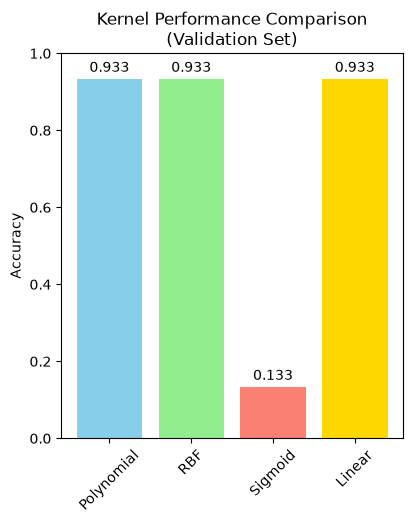

In [16]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)

kernels = list(kernels_results.keys())
accuracies = list(kernels_results.values())

bars = plt.bar(
    kernels,
    accuracies,
    color=['skyblue', 'lightgreen', 'salmon', 'gold']
)

plt.title('Kernel Performance Comparison\n(Validation Set)')
plt.ylabel('Accuracy')
plt.ylim(0, 1)

for bar, acc in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.01,
        f'{acc:.3f}',
        ha='center',
        va='bottom'
    )

plt.xticks(rotation=45)


Text(0.5, 23.185633680555554, 'Predicted Label')

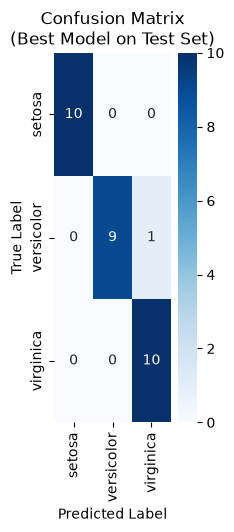

In [17]:
plt.subplot(1, 3, 2)

cm = confusion_matrix(y_test, y_test_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title('Confusion Matrix\n(Best Model on Test Set)')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')


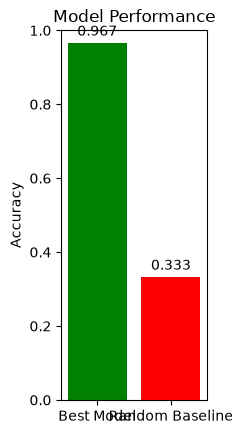

In [18]:
plt.subplot(1, 3, 3)

if best_model.kernel == 'linear' and hasattr(best_model, 'coef_'):

    feature_importance = np.abs(best_model.coef_).mean(axis=0)
    features = iris.feature_names

    bars = plt.bar(
        range(len(features)),
        feature_importance,
        color='lightcoral'
    )

    plt.title('Feature Importance\n(Linear SVM)')
    plt.xlabel('Features')
    plt.ylabel('|Coefficient|')

    plt.xticks(
        range(len(features)),
        features,
        rotation=45,
        ha='right'
    )

else:
    models = ['Best Model', 'Random Baseline']
    scores = [test_accuracy, 1 / 3]

    bars = plt.bar(
        models,
        scores,
        color=['green', 'red']
    )

    plt.title('Model Performance')
    plt.ylabel('Accuracy')
    plt.ylim(0, 1)

    for bar, score in zip(bars, scores):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.01,
            f'{score:.3f}',
            ha='center',
            va='bottom'
        )

In [19]:
plt.tight_layout()
plt.show()


<Figure size 640x480 with 0 Axes>

In [20]:
print("\n" + "=" * 50)
print("EXPERIMENT COMPLETED SUCCESSFULLY!")
print("=" * 50)


EXPERIMENT COMPLETED SUCCESSFULLY!
